In [1]:
from qiskit import QuantumRegister, QuantumCircuit, ClassicalRegister
from qiskit import quantum_info as qi
from qiskit_aer import Aer
from qiskit.visualization import array_to_latex, plot_bloch_multivector

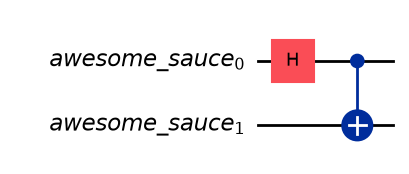

In [2]:
qr = QuantumRegister(2, 'awesome_sauce')
qc = QuantumCircuit(qr)
qc.h(qr[0])
qc.cx(qr[0], qr[1])
# qc.cx(qr[1], qr[0])
qc.draw("mpl")

In [3]:
backend = Aer.get_backend('statevector_simulator')
psi_f = backend.run(qc).result().get_statevector()
array_to_latex(psi_f, prefix="\\text{Statevector} = ")

<IPython.core.display.Latex object>

In [4]:
U = qi.Operator.from_circuit(qc).data
array_to_latex(U, prefix="\\text{Operator} = ")

<IPython.core.display.Latex object>

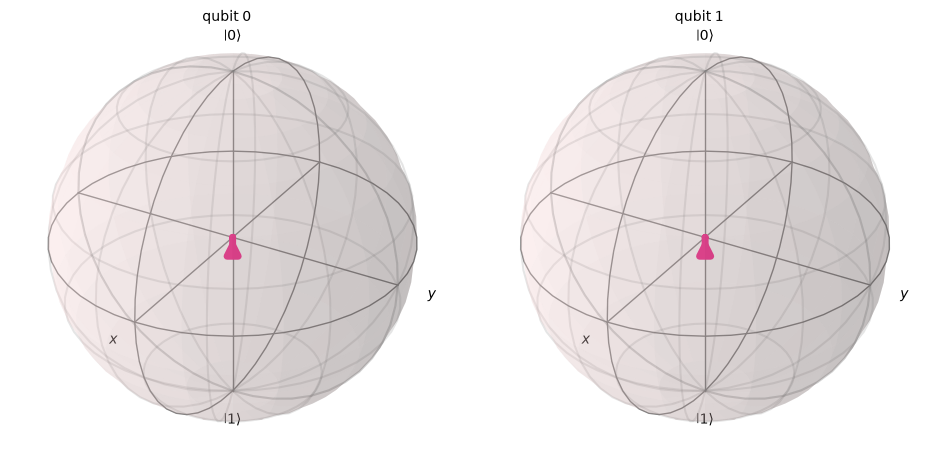

In [5]:
plot_bloch_multivector(psi_f)

In [6]:
rho_f = qi.DensityMatrix(psi_f)
array_to_latex(rho_f.data, prefix="\\text{Density Matrix} = ")

<IPython.core.display.Latex object>

In [7]:
rho_f.is_valid()

True

In [8]:
rho_f_q0 = qi.partial_trace(rho_f, [1])
array_to_latex(rho_f_q0.data, prefix="\\text{Reduced Density Matrix (Qubit 0)} = ")

<IPython.core.display.Latex object>

In [9]:
rho_f.purity()

np.complex128(1+0j)

In [10]:
rho_f_q0.purity()

np.complex128(0.5+0j)

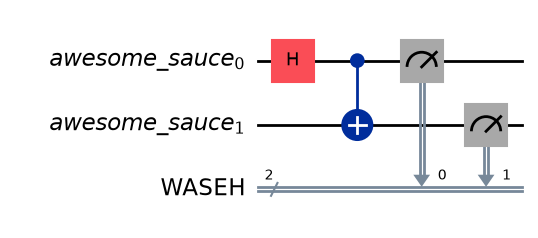

In [11]:
cr = ClassicalRegister(2, 'WASEH')
qc = QuantumCircuit(qr, cr)
qc.h(qr[0])
qc.cx(qr[0], qr[1])
qc.measure(qr, cr)
qc.draw("mpl")

In [12]:
# backend = Aer.get_backend('qasm_simulator')

# freq_00 = []
# freq_11 = []
# for i in range(10000):
#     job = backend.run(qc, shots=10000)
#     counts = job.result().get_counts(qc)
#     # print(counts)
#     freq_00.append(counts["00"]/10000)
#     freq_11.append(counts["11"]/10000)

# # print("Frequency of measuring |11> > |00> in 100 runs:", sum(freq_11)/len(freq_11), ">", sum(freq_00)/len(freq_00))

In [13]:
# from matplotlib import pyplot as plt
# import numpy as np
# plt.figure(figsize=(10, 5))
# plt.plot(np.array(freq_00)/np.array(freq_11), label="Frequency of measuring |00>")
# # plt.plot(freq_11, label="Frequency of measuring |11>")
# plt.xlabel("Run")
# plt.ylabel("Frequency")
# plt.title("Frequency of measuring |00> and |11> in 100 runs")
# plt.legend()
# plt.show()

In [14]:
from qiskit_ibm_runtime.fake_provider import FakeManilaV2

In [15]:
backend = FakeManilaV2()
job = backend.run(qc, shots=1000)
counts = job.result().get_counts(qc)
print(counts)

{'01': 20, '11': 458, '10': 39, '00': 483}


In [16]:
from qiskit.visualization import plot_histogram

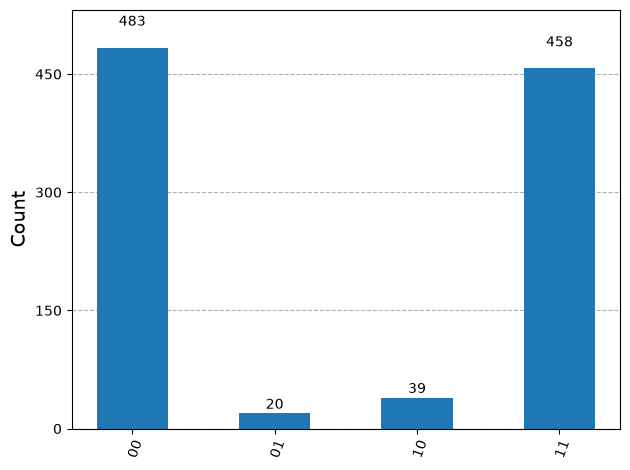

In [17]:
plot_histogram(counts)

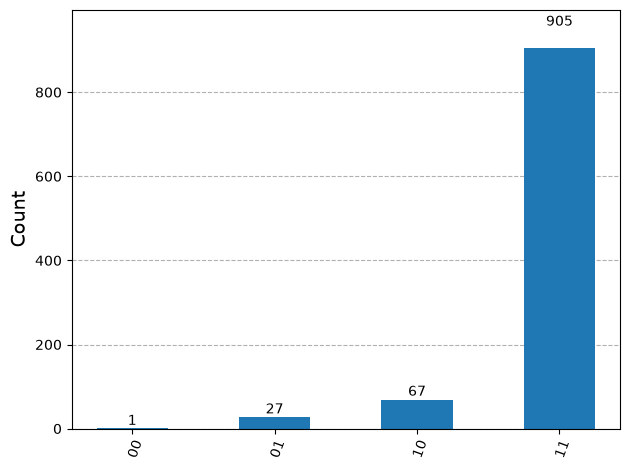

In [18]:
qc = QuantumCircuit(qr, cr)
qc.x(qr)
qc.measure(qr, cr)
counts = backend.run(qc, shots=1000).result().get_counts(qc)
plot_histogram(counts)

In [19]:
from qiskit.circuit.library import Initialize

In [20]:
# psi = qi.Statevector.from_label('1')
psi = qi.random_statevector(2, seed=2218)
array_to_latex(psi.data, prefix="\\text{Statevector} = ")

<IPython.core.display.Latex object>

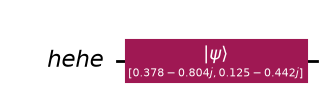

In [21]:
qr = QuantumRegister(1, 'hehe')
qc = QuantumCircuit(qr)
init_gate = Initialize(psi)
qc.append(init_gate, qr)
qc.draw("mpl")

In [22]:
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

In [23]:
backend = Aer.get_backend('qasm_simulator')
tartget = backend.target
pm = generate_preset_pass_manager(basis_gates = ["id", "rz", "rx", "cz", "x", "sx"])

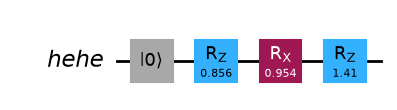

In [24]:
qc_t = pm.run(qc)
qc_t.draw("mpl")

In [25]:
backend = Aer.get_backend('statevector_simulator')
psi_f = backend.run(qc).result().get_statevector(qc)
array_to_latex(psi_f, prefix="\\text{Statevector} = ")

<IPython.core.display.Latex object>

In [26]:
I = qi.SparsePauliOp("I")
X = qi.SparsePauliOp("X")
Y = qi.SparsePauliOp("Y")
Z = qi.SparsePauliOp("Z")
array_to_latex(I, prefix="\\text{Identity Operator} = ")
array_to_latex(X, prefix="\\text{Pauli-X Operator} = ")
array_to_latex(Y, prefix="\\text{Pauli-Y Operator} = ")
array_to_latex(Z, prefix="\\text{Pauli-Z Operator} = ")

<IPython.core.display.Latex object>

### Afternoon Session

$$
I = \begin{pmatrix} 1 & 0 \\ 0 & 1\end{pmatrix}, X (\sigma_1) = \begin{pmatrix} 0 & 1 \\ 1 & 0\end{pmatrix}, Y(\sigma_2) = \begin{pmatrix} 0 & -i \\ i & 0\end{pmatrix}, Z(\sigma_3) = \begin{pmatrix}1 & 0 \\ 0 & -1 \end{pmatrix}
$$

$$
\boxed{
\sigma_i \sigma_j = \delta_{ij}I + i\varepsilon_{ijk}\sigma_k
}
$$

$$
\boxed{
[\sigma_j, \sigma_k] = 2i\varepsilon_{jkl}\sigma_l
}
$$

$$
R_x(\theta) = \exp\left(-i\frac{\theta}{2}X\right)
$$
$$
R_y(\theta) = \exp\left(-i\frac{\theta}{2}Y\right)
$$
$$
R_z(\theta) = \exp\left(-i\frac{\theta}{2}Z\right)
$$

$$
\boxed{
\exp(i\theta A) = \cos(\theta)I + i\sin(\theta)A, \text{iff } A^2 = I
}
$$

In [27]:
O = X^Y
array_to_latex(O, prefix="\\text{Operator} = ")

<IPython.core.display.Latex object>

In [28]:
O = qi.SparsePauliOp.from_list([("XII", 1.5), ("IYI", 1.0)])
array_to_latex(O, prefix="\\text{Operator} = ")

<IPython.core.display.Latex object>

$$ O = 1.5 (X \otimes I \otimes I) + 1.0 (I \otimes Y \otimes I)$$

In [29]:
O1 = (X^I)^I
O2 = X^(I^I)
O1==O2

True

In [30]:
O = qi.SparsePauliOp.from_sparse_list([("X", [2], 1.5), ("Y", [1], 1.0)], num_qubits=3)
array_to_latex(O, prefix="\\text{Operator} = ")

<IPython.core.display.Latex object>

$$ 
\exp(A+B) \ne \exp(A)\exp(B)
$$
There is an approximation to this expressions
- Lie Trotter: $\exp(A+B) = \exp(A)\exp(B)$
- Suzuki-Trotter: $\exp(A+B) = \exp(B/2) \exp(A)\exp(B/2)$


Note: if $H = Y$, then $U = e^{-iHt} = R_y(2t)$

One can also see
$$
\ket{\Psi(t)} = \cos(t)\ket{0} + \sin(t)\ket{1}
$$

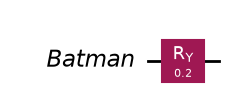

In [31]:
qr = QuantumRegister(1, "Batman")
qc = QuantumCircuit(qr)
t = 0.1
qc.ry(2*t, qr)
qc.draw("mpl")

In [32]:
backend = Aer.get_backend('statevector_simulator')
psi_f = backend.run(qc).result().get_statevector(qc)
array_to_latex(psi_f, prefix="\\text{Statevector} = ")

<IPython.core.display.Latex object>

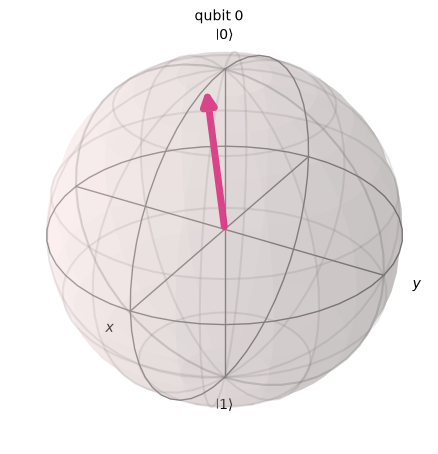

In [33]:
plot_bloch_multivector(psi_f)

Now for, 
$$ H = X + Y \to e^{H} = e^{X+Y} $$



and X and Y does not commute

Using the Trotter formula
$$
\lim_{n \to \infty} \left( e^{\frac{iAt}{n}}e^{\frac{iBt}{n}}\right)^n = e^{i(A+B)t}
$$
This means
$$
\ket{\Psi_f} = ()()(e^{\frac{iAt}{n}} e^{\frac{iBt}{n}})\ket{\Psi_i} \to \ket{\Psi_f} = e^{i(A+B)t}\ket{\Psi_i}
$$

- New Notebook (but I do not want to go to new notebook)

In [34]:
from qiskit.synthesis import LieTrotter
from qiskit.circuit.library import PauliEvolutionGate

In [35]:
I = qi.SparsePauliOp("I")
X = qi.SparsePauliOp("X")
Y = qi.SparsePauliOp("Y")
Z = qi.SparsePauliOp("Z")

In [36]:
H = (Z^Z)-0.1*(X^I)

#Check if the Hamiltonian is Hermitian
H == H.adjoint()

True

In [37]:
final_time = 20
num_timesteps = 10
dt = final_time / num_timesteps

In [38]:
trotter_step = PauliEvolutionGate(H, dt, synthesis=LieTrotter())

In [39]:
qc = QuantumCircuit(H.num_qubits)
for i in range(num_timesteps):
    qc.append(trotter_step, range(H.num_qubits))
    qc.barrier() # Graphical representation of the circuit with barriers between each Trotter step

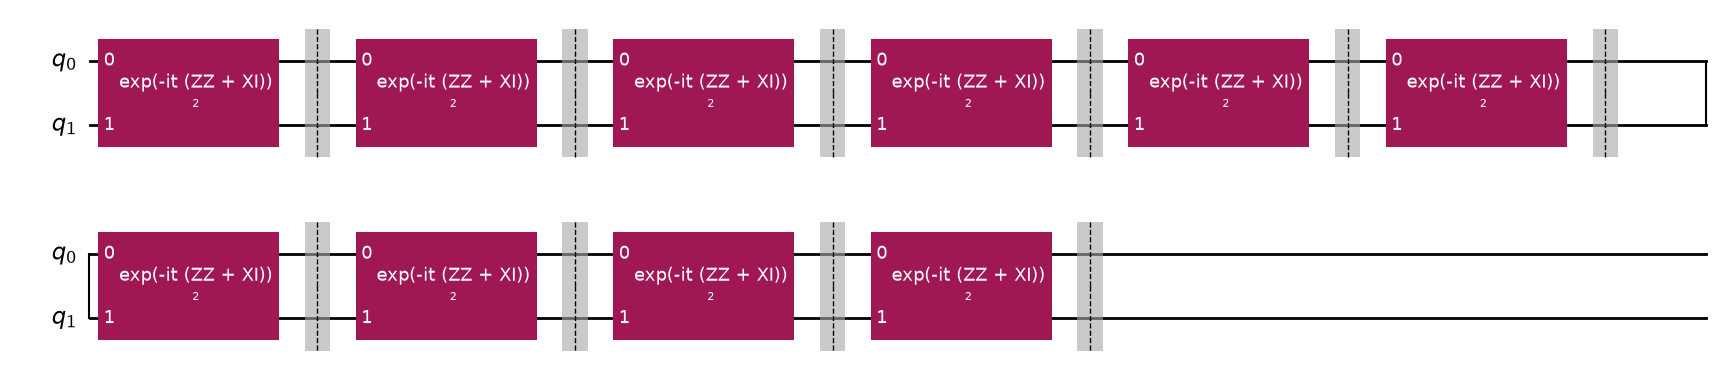

In [40]:
qc.draw("mpl")

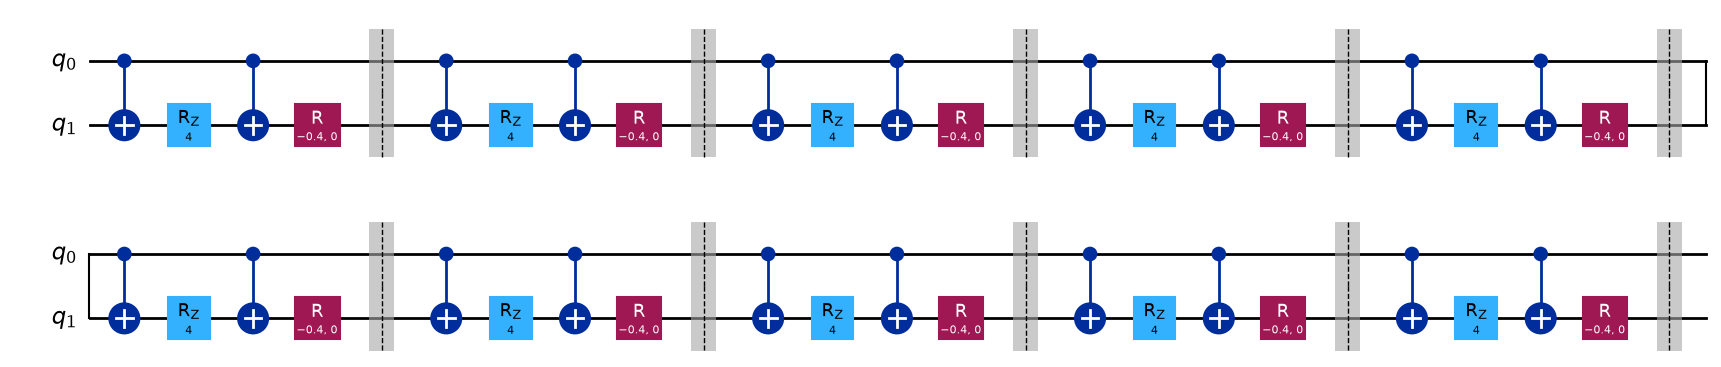

In [41]:
qc_d = qc.decompose(reps=2)
qc_d.draw("mpl")

In [42]:
print(qc_d.depth()) # This is the number of boxes
print(len(qc_d)) # This counts the barriers also

40
50


In [43]:
qc_d.num_nonlocal_gates()

20

In [44]:
backend = Aer.get_backend('statevector_simulator')
# final_state = backend.run(qc).result().get_statevector() It errors because it does not understand some of the gates (not simple enough)
final_state = backend.run(qc_d).result().get_statevector()
array_to_latex(final_state, precision=6)

<IPython.core.display.Latex object>

In [45]:
mat = H.to_matrix()
array_to_latex(mat)

<IPython.core.display.Latex object>

In [46]:
import numpy as np
exact_times = np.linspace(0, final_time, 101)
# print(exact_times)

In [47]:
initial_state = qi.Statevector.from_int(0, dims= 2**H.num_qubits)
array_to_latex(initial_state)

<IPython.core.display.Latex object>

In [48]:
import scipy as sp
exact_evolution = [initial_state.evolve(sp.linalg.expm(-1j* time * mat)) for time in exact_times]

In [49]:
array_to_latex(exact_evolution[-1], precision=6)

<IPython.core.display.Latex object>

In [50]:
print(qi.state_fidelity(final_state, exact_evolution[-1]))

0.9351119121777253


In [51]:
from qiskit.synthesis import SuzukiTrotter

In [52]:
trotter_step = PauliEvolutionGate(H, dt, synthesis= SuzukiTrotter(order=4))

In [53]:
qc = QuantumCircuit(H.num_qubits)
for i in range(num_timesteps):
    qc.append(trotter_step, range(H.num_qubits))
    qc.barrier()

In [54]:
qc_t = qc.decompose(reps=2)

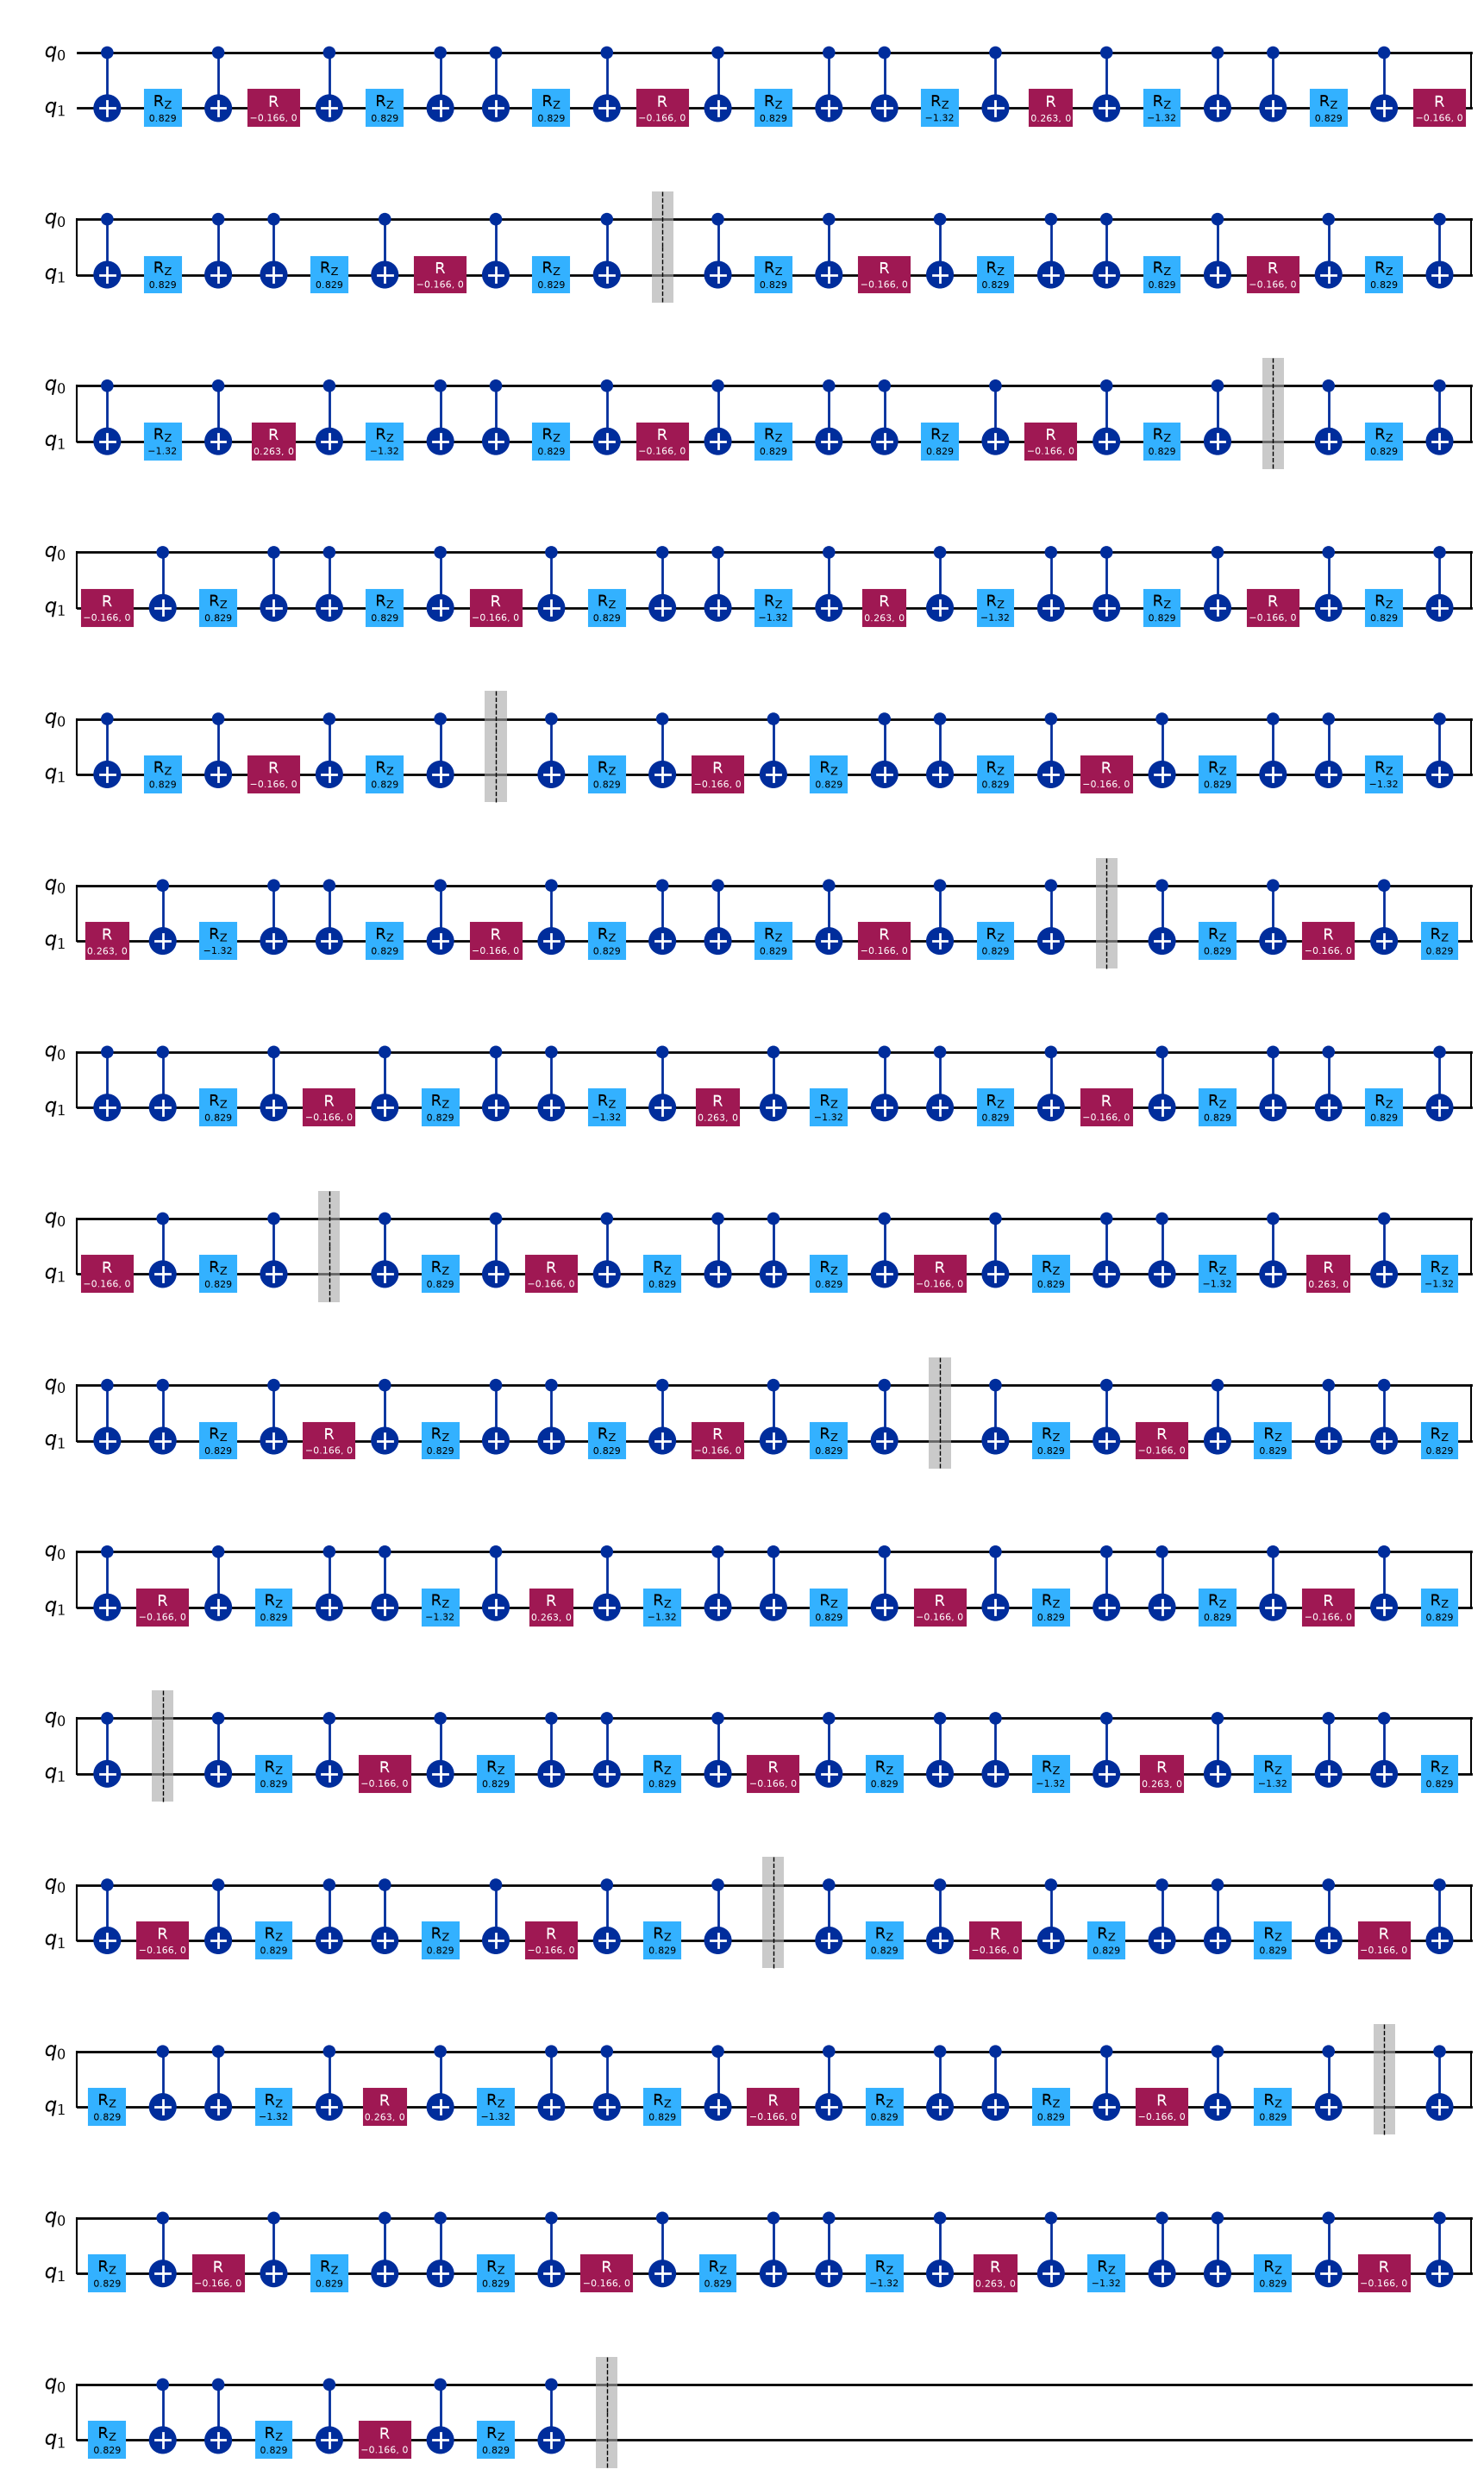

In [55]:
qc_t.draw("mpl")

In [56]:
qc_t.depth()

350

In [57]:
final_state = backend.run(qc_t).result().get_statevector()
array_to_latex(final_state, precision=6)

<IPython.core.display.Latex object>

In [58]:
print(qi.state_fidelity(final_state, exact_evolution[-1]))

0.9998543205286909


### Ising model

import tutorial_magics
%qiskit_version_table

In [63]:
import qiskit
print(qiskit.__version__)

2.6.2
